<!-- Cell 1 -->
# Ariel: improvement models, tuning, and experiment plan
**Notebook owner: Ariel Gholar.** Uses Jordan Rivera's shared loading/filtering functions and Logan Calder's proposed chronological split without changing either.

**Role in the milestone:** select two models that improve on the baseline, define their tuning ranges, design the experiments, and report preliminary validation results.

**Question this notebook answers:** Do flexible models (gradient-boosted trees, a feedforward neural network) give *better-calibrated* conversion probabilities than the baseline on a future season?

**Data discipline:** tuning uses training seasons 2015–2022 only (season-based cross-validation). The 2023 validation season is used once per model for comparison. **The 2024–2025 test seasons are never touched here.**

Outputs are exported to `reports/ariel_models/`.

In [1]:
# Cell 2
from pathlib import Path
import sys
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from scipy.stats import loguniform, randint
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import RandomizedSearchCV
from sklearn.metrics import log_loss, brier_score_loss, roc_auc_score
import tensorflow as tf
from tensorflow import keras

ROOT = Path.cwd().resolve()
if not (ROOT / "nfl_project").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "nfl_project").is_dir(), "Run from project root or notebooks/."
sys.path.insert(0, str(ROOT))
from nfl_project.data import load_data, process_4th_down_data, TARGET_COLUMN

OUT = ROOT / "reports" / "ariel_models"
CACHE = ROOT / "data" / "ariel_models"
OUT.mkdir(parents=True, exist_ok=True)
CACHE.mkdir(parents=True, exist_ok=True)
plt.rcParams.update({"figure.dpi": 120, "font.size": 10, "axes.spines.top": False, "axes.spines.right": False})

SEED = 207
np.random.seed(SEED)
tf.random.set_seed(SEED)
SEASONS = list(range(2015, 2026))

I0000 00:00:1792273857.562204     180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792273857.572748     180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


I0000 00:00:1792273862.080449     180 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792273862.086556     180 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.


<!-- Cell 3 -->
## Load data and apply the agreed split
Same seasons, shared filter, and split as Logan's EDA. Seasons are loaded and filtered **one at a time** so the full 532k-play table never sits in memory; only the ~7.4k fourth-down attempts are cached, under the ignored `data/ariel_models/` folder. The asserts confirm the partition sizes match the milestone document (4,887 / 823 / 1,723).

In [2]:
# Cell 4
attempts_cache = CACHE / "attempts_2015_2025.parquet"
if attempts_cache.exists():
    attempts = pd.read_parquet(attempts_cache)
else:
    attempts = pd.concat([process_4th_down_data(load_data(s)) for s in SEASONS], ignore_index=True)
    attempts.to_parquet(attempts_cache, index=False)

train = attempts[attempts["season"].between(2015, 2022)].reset_index(drop=True)
val = attempts[attempts["season"] == 2023].reset_index(drop=True)
n_test = int(attempts["season"].between(2024, 2025).sum())  # count only; test rows are not kept

print(f"train={len(train):,}  validation={len(val):,}  test (untouched)={n_test:,}")
assert (len(train), len(val), n_test) == (4887, 823, 1723), "Split no longer matches the milestone counts."

train=4,887  validation=823  test (untouched)=1,723


<!-- Cell 5 -->
## Features
Pre-snap predictors only (anything recorded after the snap would leak the outcome).

- **Numeric:** yards to go, field position, quarter, time remaining, score differential.
- **Team identity (optional):** `posteam` / `defteam` one-hot encoded. Team quality changes across seasons, so team indicators learned on 2015–2022 may not carry over to 2023. They are treated as an **experiment** (on vs. off) rather than assumed.

> **TODO (coordinate with Emily):** use the same feature list and preprocessing as the baseline so the comparison is like-for-like. Update `NUMERIC` / `CATEGORICAL` below if she changes them.

In [3]:
# Cell 6
NUMERIC = ["ydstogo", "yardline_100", "qtr", "game_seconds_remaining", "score_differential"]
CATEGORICAL = ["posteam", "defteam"]
USE_TEAMS = False  # experiment toggle; rerun with True and compare CV log loss

FEATURES = NUMERIC + (CATEGORICAL if USE_TEAMS else [])
X_train, y_train = train[FEATURES], train[TARGET_COLUMN].to_numpy()
X_val, y_val = val[FEATURES], val[TARGET_COLUMN].to_numpy()

def make_preprocessor():
    """Scale numerics and one-hot teams. Fit on training folds only (inside the pipeline)."""
    steps = [("num", StandardScaler(), NUMERIC)]
    if USE_TEAMS:
        steps.append(("cat", OneHotEncoder(handle_unknown="ignore"), CATEGORICAL))
    return ColumnTransformer(steps)

print(f"{len(FEATURES)} input columns: {FEATURES}")
print(f"Training base rate: {y_train.mean():.3f}")

5 input columns: ['ydstogo', 'yardline_100', 'qtr', 'game_seconds_remaining', 'score_differential']
Training base rate: 0.518


<!-- Cell 7 -->
## Evaluation metrics
The model's output feeds a break-even go-for-it decision, so **the probability itself must be accurate**, not just the ranking.

| Metric | Role | Why |
|---|---|---|
| Log loss | **Primary** (tuning + selection) | Proper scoring rule; heavily penalizes confident wrong probabilities |
| Brier score | Secondary | Mean squared error of the probability; easier to interpret |
| Expected calibration error (ECE) | Diagnostic | Average gap between predicted and observed rates across 10 bins |
| Calibration slope | Diagnostic | Slope from regressing outcomes on the model's log-odds: 1 = ideal, >1 = predictions too compressed toward 50%, <1 = overconfident |
| ROC-AUC | Diagnostic | Ranking quality only; a model can rank well and still be miscalibrated |

Accuracy at a 0.5 threshold is deliberately not used: it says nothing about whether a 60% prediction really converts 60% of the time.

**ECE is not a ranking metric.** A constant prediction equal to the overall rate has near-zero ECE while carrying no information, so the base rate will "win" on ECE. Models are ranked on log loss; ECE and calibration slope only diagnose *how* a model is miscalibrated.

In [4]:
# Cell 8
def expected_calibration_error(y, p, n_bins=10):
    bins = np.clip((p * n_bins).astype(int), 0, n_bins - 1)
    ece = 0.0
    for b in range(n_bins):
        mask = bins == b
        if mask.any():
            ece += mask.mean() * abs(y[mask].mean() - p[mask].mean())
    return ece

def calibration_slope(y, p):
    """Logistic regression of outcomes on the model's log-odds (unpenalized). NaN for constant predictions."""
    if np.ptp(p) < 1e-9:
        return np.nan
    logit = np.log(np.clip(p, 1e-6, 1 - 1e-6) / np.clip(1 - p, 1e-6, 1))
    return LogisticRegression(C=1e6).fit(logit.reshape(-1, 1), y).coef_[0, 0]

def score(name, y, p):
    return {"model": name,
            "log_loss": log_loss(y, p, labels=[0, 1]),
            "brier": brier_score_loss(y, p),
            "ece": expected_calibration_error(y, p),
            "cal_slope": calibration_slope(y, p),
            "roc_auc": roc_auc_score(y, p)}

<!-- Cell 9 -->
## Validation design for tuning
Tuning on the single 2023 season would be noisy (823 plays) and would spend the validation set on dozens of configurations. Instead, hyperparameters are tuned with **expanding-window cross-validation by season inside 2015–2022**:

| Fold | Fit on | Score on |
|---|---|---|
| 1 | 2015–2018 | 2019 |
| 2 | 2015–2019 | 2020 |
| 3 | 2015–2020 | 2021 |
| 4 | 2015–2021 | 2022 |

Every fold scores a season *later* than the data it was fit on, which mirrors how the model is used, and keeps all plays from one game in the same fold. The 2023 validation season is then used **once per finalist** to compare models.

In [5]:
# Cell 10
def season_folds(seasons, first_holdout=2019, last_holdout=2022):
    """Expanding-window (train_idx, holdout_idx) pairs, one per holdout season."""
    seasons = np.asarray(seasons)
    return [(np.where(seasons < s)[0], np.where(seasons == s)[0])
            for s in range(first_holdout, last_holdout + 1)]

CV_FOLDS = season_folds(train["season"])
for (tr, ho), s in zip(CV_FOLDS, range(2019, 2023)):
    print(f"holdout {s}: fit on {len(tr):,}, score on {len(ho):,}")

holdout 2019: fit on 2,031, score on 612
holdout 2020: fit on 2,643, score on 677
holdout 2021: fit on 3,320, score on 805
holdout 2022: fit on 4,125, score on 762


<!-- Cell 11 -->
## Reference points: base rate and baseline
Two references every improvement model must beat:

1. **Base rate:** predict the training conversion rate (≈51.8%) for every play. Any model worse than this has learned nothing useful.
2. **Baseline (owned by Emily):** if her notebook exports validation predictions to `reports/emily_baseline/val_predictions.csv` (columns `game_id`, `play_id`, `p_baseline`), they are loaded here. Until then, a *reference copy* of a plain logistic regression is fit so this notebook runs end to end. Emily's notebook is the source of truth for the baseline.

> **TODO:** agree the export path/format with Emily, then delete the fallback.

In [6]:
# Cell 12
baseline_file = ROOT / "reports" / "emily_baseline" / "val_predictions.csv"
p_base_rate = np.full(len(y_val), y_train.mean())

if baseline_file.exists():
    emily = pd.read_csv(baseline_file)
    p_baseline = val[["game_id", "play_id"]].merge(emily, on=["game_id", "play_id"], how="left")["p_baseline"].to_numpy()
    assert not np.isnan(p_baseline).any(), "Baseline predictions do not cover every validation play."
    baseline_source = "Emily's exported predictions"
    BASELINE = "Baseline"
else:
    ref = Pipeline([("prep", make_preprocessor()), ("clf", LogisticRegression(max_iter=1000))])
    ref.fit(X_train, y_train)
    p_baseline = ref.predict_proba(X_val)[:, 1]
    baseline_source = "reference logistic regression (placeholder until Emily's export exists)"
    BASELINE = "Baseline (reference LR)"

print(f"Baseline source: {baseline_source}")

Baseline source: reference logistic regression (placeholder until Emily's export exists)


<!-- Cell 13 -->
## Improvement 1: gradient-boosted trees
**Why it fits:** EDA shows conversion falling steeply and non-linearly with distance, a drop inside the opponent's 20, and situations (score × time remaining) whose effect depends on each other. Trees learn these thresholds and interactions without hand-built features, handle unscaled and skewed inputs, and are strong on small tabular data. scikit-learn's `HistGradientBoostingClassifier` is used so the shared environment needs no new dependency.

| Hyperparameter | Range | Controls |
|---|---|---|
| `learning_rate` | log-uniform 0.003–0.3 | step size per tree |
| `max_iter` | 100–1000 | number of trees (more needed at small learning rates) |
| `max_leaf_nodes` | 2–32 | tree complexity; 2 = stumps, i.e. no interactions |
| `min_samples_leaf` | 20–500 | smallest group a leaf can describe (regularization) |
| `l2_regularization` | log-uniform 1e-3–10 | shrinks leaf values |

**Tuning:** randomized search, 60 draws, scored by log loss on the season folds.

Small leaves on ~5k rows would overfit, so `min_samples_leaf` starts at 20. An earlier, narrower search (learning rate ≥ 0.01, leaves ≥ 4, `min_samples_leaf` ≤ 200) chose values at the edge of all three ranges, which means it wanted a simpler, more regularized model than the space allowed. The ranges were widened in that direction. The cell after the search flags any parameter that still lands at a boundary.

In [7]:
# Cell 14
gbm = Pipeline([("prep", make_preprocessor()),
                ("clf", HistGradientBoostingClassifier(random_state=SEED))])
gbm_space = {
    "clf__learning_rate": loguniform(0.003, 0.3),
    "clf__max_iter": randint(100, 1001),
    "clf__max_leaf_nodes": randint(2, 33),
    "clf__min_samples_leaf": randint(20, 501),
    "clf__l2_regularization": loguniform(1e-3, 10),
}
GBM_BOUNDS = {"clf__learning_rate": (0.003, 0.3), "clf__max_iter": (100, 1000), "clf__max_leaf_nodes": (2, 32),
              "clf__min_samples_leaf": (20, 500), "clf__l2_regularization": (1e-3, 10)}
gbm_search = RandomizedSearchCV(gbm, gbm_space, n_iter=60, scoring="neg_log_loss",
                                cv=CV_FOLDS, random_state=SEED, n_jobs=-1, refit=True)
gbm_search.fit(X_train, y_train)

gbm_cv = (pd.DataFrame(gbm_search.cv_results_)
          .assign(cv_log_loss=lambda d: -d.mean_test_score)
          .sort_values("cv_log_loss"))
print("Best CV log loss:", round(gbm_cv.cv_log_loss.iloc[0], 4))
display(pd.Series(gbm_search.best_params_, name="best GBM params"))
gbm_cv.filter(regex="param_|cv_log_loss|std_test_score").head(10).to_csv(OUT / "gbm_top10_configs.csv", index=False)

# Flag any chosen value in the outer 10% of its range (log scale for log-uniform parameters).
for k, v in gbm_search.best_params_.items():
    lo, hi = GBM_BOUNDS[k]
    log_scale = k in ("clf__learning_rate", "clf__l2_regularization")
    pos = (np.log(v) - np.log(lo)) / (np.log(hi) - np.log(lo)) if log_scale else (v - lo) / (hi - lo)
    if pos < 0.1 or pos > 0.9:
        print(f"Note: {k}={v:.4g} sits near the {'lower' if pos < 0.1 else 'upper'} edge of its range")

Best CV log loss: 0.6513


clf__l2_regularization      0.031766
clf__learning_rate          0.009541
clf__max_iter             713.000000
clf__max_leaf_nodes        23.000000
clf__min_samples_leaf     374.000000
Name: best GBM params, dtype: float64

<!-- Cell 15 -->
## Improvement 2: feedforward neural network
**Why it fits:** a small FFNN learns smooth non-linear interactions (unlike the step functions trees produce), which suits continuous inputs like time remaining and score margin, and its sigmoid output is a probability trained directly on log loss. It also extends the Keras work from the course.

**Risk:** ~4.9k training plays is small for a neural net, so capacity is kept low and regularization is part of the search.

| Hyperparameter | Values | Controls |
|---|---|---|
| hidden layers | 1, 2 | depth |
| units per layer | 8, 16, 32, 64 | width |
| dropout | 0.0–0.4 | regularization |
| L2 weight penalty | 1e-5–1e-2 (log) | regularization |
| learning rate (Adam) | 3e-4–3e-3 (log) | optimizer step |

Epochs are chosen by early stopping (patience 15) on each fold's holdout season. 12 random configurations × 4 folds.

The search budget is smaller than the GBM's 60 draws because each FFNN configuration costs 4 full training runs, and because the configurations perform nearly identically (the spread in CV log loss across all 12 is printed below), so additional draws would buy little.

In [8]:
# Cell 16
def build_ffnn(n_inputs, layers, units, dropout, l2, lr):
    model = keras.Sequential([keras.Input(shape=(n_inputs,))])
    for _ in range(int(layers)):
        model.add(keras.layers.Dense(int(units), activation="relu",
                                     kernel_regularizer=keras.regularizers.l2(l2)))
        if dropout > 0:
            model.add(keras.layers.Dropout(dropout))
    model.add(keras.layers.Dense(1, activation="sigmoid"))
    model.compile(optimizer=keras.optimizers.Adam(lr), loss="binary_crossentropy")
    return model

def sample_configs(n, rng):
    return [{"layers": int(rng.choice([1, 2])),
             "units": int(rng.choice([8, 16, 32, 64])),
             "dropout": float(rng.uniform(0.0, 0.4)),
             "l2": float(10 ** rng.uniform(-5, -2)),
             "lr": float(10 ** rng.uniform(np.log10(3e-4), np.log10(3e-3)))}
            for _ in range(n)]

def fit_ffnn(cfg, X_fit, y_fit, X_hold=None, y_hold=None, epochs=300):
    keras.utils.set_random_seed(SEED)
    model = build_ffnn(X_fit.shape[1], cfg["layers"], cfg["units"], cfg["dropout"], cfg["l2"], cfg["lr"])
    kwargs = {}
    if X_hold is not None:
        kwargs = {"validation_data": (X_hold, y_hold),
                  "callbacks": [keras.callbacks.EarlyStopping(patience=15, restore_best_weights=True)]}
    hist = model.fit(X_fit, y_fit, epochs=epochs, batch_size=128, verbose=0, **kwargs)
    best_epoch = int(np.argmin(hist.history["val_loss"])) + 1 if X_hold is not None else epochs
    return model, best_epoch

In [9]:
# Cell 17
rng = np.random.default_rng(SEED)
rows = []
for i, cfg in enumerate(sample_configs(12, rng)):
    fold_losses, fold_epochs = [], []
    for tr, ho in CV_FOLDS:
        prep = make_preprocessor().fit(X_train.iloc[tr])          # fit scaling on the fold's training seasons only
        Xa, Xb = prep.transform(X_train.iloc[tr]), prep.transform(X_train.iloc[ho])
        model, ep = fit_ffnn(cfg, Xa, y_train[tr], Xb, y_train[ho])
        p = model.predict(Xb, verbose=0).ravel()
        fold_losses.append(log_loss(y_train[ho], p, labels=[0, 1]))
        fold_epochs.append(ep)
    rows.append({**cfg, "cv_log_loss": np.mean(fold_losses), "cv_std": np.std(fold_losses),
                 "median_epochs": int(np.median(fold_epochs)),
                 **{f"fold_{s}": l for s, l in zip(range(2019, 2023), fold_losses)}})
    print(f"config {i+1:2d}/12  cv log loss={rows[-1]['cv_log_loss']:.4f}")

ffnn_cv = pd.DataFrame(rows).sort_values("cv_log_loss")
ffnn_cv.to_csv(OUT / "ffnn_configs.csv", index=False)
ffnn_spread = ffnn_cv.cv_log_loss.max() - ffnn_cv.cv_log_loss.min()
print(f"Spread across all 12 configurations: {ffnn_spread:.4f}")
display(ffnn_cv.head())

config  1/12  cv log loss=0.6509


config  2/12  cv log loss=0.6507


config  3/12  cv log loss=0.6504


config  4/12  cv log loss=0.6505


config  5/12  cv log loss=0.6518


...

config  9/12  cv log loss=0.6516


config 10/12  cv log loss=0.6504


config 11/12  cv log loss=0.6505


config 12/12  cv log loss=0.6509
Spread across all 12 configurations: 0.0014


,layers,units,dropout,l2,lr,cv_log_loss,cv_std,median_epochs,fold_2019,fold_2020,fold_2021,fold_2022
9,1,32,0.129578,0.000214,0.001401,0.650404,0.005365,12,0.659131,0.644958,0.647364,0.650161
2,1,32,0.399513,0.000295,0.001157,0.650450,0.005308,35,0.659288,0.646015,0.646632,0.649863
3,1,32,0.214936,0.000015,0.000655,0.650454,0.005366,28,0.659336,0.645237,0.647539,0.649703
10,2,8,0.111486,0.000047,0.002634,0.650486,0.005205,27,0.658240,0.645041,0.646509,0.652154
1,2,64,0.191806,0.003353,0.000580,0.650679,0.005501,154,0.659726,0.646052,0.646469,0.650469


<!-- Cell 18 -->
## Season-CV comparison against logistic regression
The 2023 comparison below rests on 823 plays. The same four season folds give a second, larger comparison: about 2,900 held-out plays (2019–2022), with every model scored on exactly the same plays.

Logistic regression has no tuning, so its CV score is unbiased. The GBM and FFNN scores are each the **best of many configurations**, which flatters them slightly. If the tuned models still don't beat logistic regression here, the gap isn't about tuning.

In [10]:
# Cell 19
lr_cv = Pipeline([("prep", make_preprocessor()), ("clf", LogisticRegression(max_iter=1000))])
lr_folds = [log_loss(y_train[ho], lr_cv.fit(X_train.iloc[tr], y_train[tr]).predict_proba(X_train.iloc[ho])[:, 1], labels=[0, 1])
            for tr, ho in CV_FOLDS]
best_gbm_row = gbm_cv.iloc[0]
gbm_folds = [-best_gbm_row[f"split{i}_test_score"] for i in range(len(CV_FOLDS))]
nn_folds = [ffnn_cv.iloc[0][f"fold_{s}"] for s in range(2019, 2023)]

cv_compare = pd.DataFrame({"Logistic regression": lr_folds, "Gradient boosting (best)": gbm_folds,
                           "Feedforward NN (best)": nn_folds}, index=[f"holdout {s}" for s in range(2019, 2023)])
cv_compare.loc["mean"] = cv_compare.mean()
cv_compare = cv_compare.round(4)
cv_compare.to_csv(OUT / "cv_comparison.csv")
display(cv_compare)

,Logistic regression,Gradient boosting (best),Feedforward NN (best)
holdout 2019,0.6622,0.6635,0.6591
holdout 2020,0.6461,0.6498,0.6450
holdout 2021,0.6511,0.6429,0.6474
holdout 2022,0.6495,0.6488,0.6502
mean,0.6522,0.6513,0.6504


<!-- Cell 20 -->
## Preliminary results on the 2023 validation season
Each finalist is refit on all of 2015–2022 with its best configuration (the FFNN trains for the median early-stopping epoch from CV, so 2023 is not used to pick epochs), then scored **once** on 2023.

In [11]:
# Cell 21
best_cfg = ffnn_cv.iloc[0].to_dict()
ffnn_prep = make_preprocessor().fit(X_train)
ffnn_model, _ = fit_ffnn(best_cfg, ffnn_prep.transform(X_train), y_train, epochs=int(best_cfg["median_epochs"]))

preds = {
    "Base rate": p_base_rate,
    BASELINE: p_baseline,
    "Gradient boosting": gbm_search.predict_proba(X_val)[:, 1],
    "Feedforward NN": ffnn_model.predict(ffnn_prep.transform(X_val), verbose=0).ravel(),
}
results = pd.DataFrame([score(k, y_val, v) for k, v in preds.items()]).set_index("model").round(4)
results.to_csv(OUT / "validation_metrics.csv")
display(results)

,log_loss,brier,ece,cal_slope,roc_auc
model,,,,,
Base rate,0.6924,0.2496,0.0005,NaN,0.5000
Baseline (reference LR),0.6226,0.2174,0.0372,1.4846,0.6945
Gradient boosting,0.6267,0.2186,0.0331,1.2601,0.6965
Feedforward NN,0.6200,0.2159,0.0362,1.5145,0.7048


<!-- Cell 22 -->
## Is the difference real? Game-level bootstrap
With 823 validation plays, small log-loss gaps can be noise. Plays within a game are correlated, so the bootstrap **resamples whole games** (not individual plays) and reports a 95% interval for each model's log-loss improvement over the baseline. An interval that excludes 0 indicates a reliable improvement.

In [12]:
# Cell 23
def game_bootstrap_delta(y, p_model, p_ref, games, n_boot=2000, seed=SEED):
    """Paired bootstrap of mean log loss (reference minus model); positive = model is better."""
    eps = 1e-15
    ll = lambda p: -(y * np.log(np.clip(p, eps, 1)) + (1 - y) * np.log(np.clip(1 - p, eps, 1)))
    diff = pd.Series(ll(p_ref) - ll(p_model)).groupby(np.asarray(games))
    g_sum, g_n = diff.sum().to_numpy(), diff.size().to_numpy()
    r = np.random.default_rng(seed)
    idx = r.integers(0, len(g_sum), size=(n_boot, len(g_sum)))
    boots = g_sum[idx].sum(1) / g_n[idx].sum(1)
    return g_sum.sum() / g_n.sum(), *np.percentile(boots, [2.5, 97.5])

rows = []
for name in ["Gradient boosting", "Feedforward NN"]:
    est, lo, hi = game_bootstrap_delta(y_val, preds[name], preds[BASELINE], val["game_id"])
    rows.append({"model": name, "logloss_improvement_vs_baseline": est, "ci_low": lo, "ci_high": hi})
boot = pd.DataFrame(rows).set_index("model").round(4)
boot.to_csv(OUT / "bootstrap_vs_baseline.csv")
display(boot)

,logloss_improvement_vs_baseline,ci_low,ci_high
model,,,
Gradient boosting,-0.0041,-0.0132,0.0051
Feedforward NN,0.0026,-0.0012,0.0064


<!-- Cell 24 -->
## Calibration check
A reliability diagram bins validation plays by predicted probability and plots the observed conversion rate in each bin. Points on the diagonal mean "a 60% prediction converts about 60% of the time", which is the property the break-even decision depends on.

**How to read it:** points *below* the diagonal at low predictions and *above* it at high predictions mean the model's probabilities are squeezed toward 50%: true long shots are worse than predicted and true favorites better. The calibration slope in the results table summarizes this in one number (above 1 = squeezed). With 823 plays, each bin holds roughly 50–150 plays, so small wiggles are noise; only a consistent pattern across bins and models is meaningful.

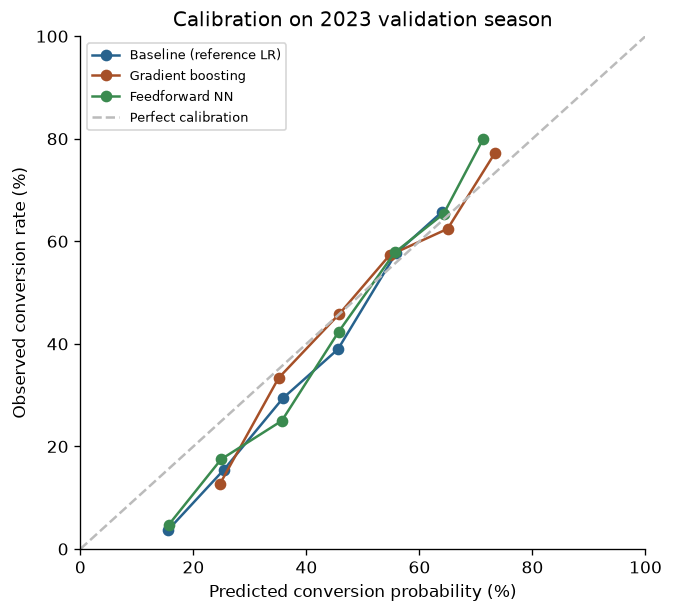

In [13]:
# Cell 25
fig, ax = plt.subplots(figsize=(5.5, 5), layout="constrained")
edges = np.linspace(0, 1, 11)
for (name, p), color in zip(preds.items(), ["#999999", "#27628d", "#a65028", "#3a8a4f"]):
    if name == "Base rate":
        continue
    b = np.clip(np.digitize(p, edges) - 1, 0, 9)
    tab = pd.DataFrame({"b": b, "p": p, "y": y_val}).groupby("b").agg(p=("p", "mean"), y=("y", "mean"), n=("y", "size"))
    tab = tab[tab.n >= 15]  # hide bins too sparse to read
    ax.plot(tab.p * 100, tab.y * 100, "o-", color=color, label=name)
ax.plot([0, 100], [0, 100], "--", color="#bbbbbb", label="Perfect calibration")
ax.set(xlabel="Predicted conversion probability (%)", ylabel="Observed conversion rate (%)",
       title="Calibration on 2023 validation season", xlim=(0, 100), ylim=(0, 100))
ax.legend(fontsize=8)
fig.savefig(OUT / "01_calibration_validation.png", dpi=180, bbox_inches="tight")
plt.show()
plt.close(fig)

<!-- Cell 26 -->
## Is 2023 unusual? Calibration slope by season
Every model is squeezed toward 50% on 2023, including the lightly regularized logistic regression. That pattern points to the *season*, not the model. To test it, the logistic regression is scored the same way on every held-out season: each CV season (fit on all earlier seasons), plus 2023 (fit on 2015–2022). Each slope gets a 95% game-level bootstrap interval. If only 2023's interval excludes 1, the shift is specific to that season.

In [14]:
# Cell 27
def slope_ci(y, p, games, n_boot=500, seed=SEED):
    """Calibration slope with a 95% interval from resampling whole games."""
    games = np.asarray(games)
    uniq = np.unique(games)
    rows_by_game = {g: np.where(games == g)[0] for g in uniq}
    r = np.random.default_rng(seed)
    boots = []
    for _ in range(n_boot):
        idx = np.concatenate([rows_by_game[g] for g in r.choice(uniq, size=len(uniq))])
        boots.append(calibration_slope(y[idx], p[idx]))
    return calibration_slope(y, p), *np.percentile(boots, [2.5, 97.5])

season_rows = []
for (tr, ho), s in zip(CV_FOLDS, range(2019, 2023)):
    p = lr_cv.fit(X_train.iloc[tr], y_train[tr]).predict_proba(X_train.iloc[ho])[:, 1]
    est, lo, hi = slope_ci(y_train[ho], p, train["game_id"].iloc[ho])
    season_rows.append({"holdout": str(s), "plays": len(ho), "slope": est, "ci_low": lo, "ci_high": hi})
p23 = lr_cv.fit(X_train, y_train).predict_proba(X_val)[:, 1]
est, lo, hi = slope_ci(y_val, p23, val["game_id"])
season_rows.append({"holdout": "2023 (validation)", "plays": len(y_val), "slope": est, "ci_low": lo, "ci_high": hi})

season_slopes = pd.DataFrame(season_rows).set_index("holdout").round(2)
season_slopes["excludes_1"] = (season_slopes.ci_low > 1) | (season_slopes.ci_high < 1)
season_slopes.to_csv(OUT / "calibration_slope_by_season.csv")
display(season_slopes)

,plays,slope,ci_low,ci_high,excludes_1
holdout,,,,,
2019,612,0.87,0.60,1.23,False
2020,677,1.02,0.75,1.35,False
2021,805,0.98,0.67,1.32,False
2022,762,1.07,0.79,1.40,False
2023 (validation),823,1.48,1.17,1.79,True


<!-- Cell 28 -->
**What changed in 2023?** Observed conversion rates by distance for every season used so far (training plus validation; the test seasons stay untouched). If long attempts converted less often and short ones more often in 2023 than before, outcomes were more predictable than the 2015–2022 relationships imply, and the models' predictions would look squeezed in exactly the way the slope shows.

In [15]:
# Cell 29
seen = pd.concat([train, val], ignore_index=True)
seen["distance"] = pd.cut(seen["ydstogo"], [-np.inf, 1, 2, 3, 5, 10, np.inf],
                          labels=["1", "2", "3", "4–5", "6–10", "11+"])
by_season = seen.pivot_table(index="season", columns="distance", values=TARGET_COLUMN, aggfunc="mean", observed=False)
counts = seen.pivot_table(index="season", columns="distance", values=TARGET_COLUMN, aggfunc="size", observed=False)
by_season.round(3).to_csv(OUT / "conversion_by_distance_and_season.csv")
display((by_season * 100).round(1).astype(str) + "% (n=" + counts.astype(str) + ")")

distance,1,2,3,4–5,6–10,11+
season,,,,,,
2015,64.6% (n=164),50.9% (n=57),32.6% (n=43),46.2% (n=78),41.8% (n=98),21.6% (n=51)
2016,62.4% (n=181),61.7% (n=60),61.2% (n=49),54.2% (n=59),28.9% (n=90),23.9% (n=46)
2017,65.0% (n=177),46.2% (n=52),45.0% (n=40),43.5% (n=62),35.1% (n=111),27.6% (n=58)
2018,72.4% (n=225),62.7% (n=67),52.1% (n=48),42.7% (n=75),48.5% (n=97),23.3% (n=43)
2019,59.2% (n=218),56.0% (n=84),57.8% (n=45),40.0% (n=95),34.2% (n=114),23.2% (n=56)
2020,66.6% (n=296),60.9% (n=87),53.3% (n=45),49.4% (n=89),38.6% (n=101),27.1% (n=59)
2021,67.5% (n=326),59.8% (n=127),35.7% (n=56),51.5% (n=99),39.6% (n=134),17.5% (n=63)
2022,65.6% (n=317),51.9% (n=108),46.8% (n=77),50.6% (n=89),34.9% (n=109),16.1% (n=62)
2023,69.9% (n=312),56.1% (n=132),57.3% (n=75),43.9% (n=114),30.6% (n=121),7.2% (n=69)


<!-- Cell 30 -->
## Model selection rule and remaining experiments
**Selection rule (stated before looking at test data):**
1. Rank finalists by 2023 validation log loss.
2. Prefer the simpler model unless the more complex one's bootstrap interval for improvement excludes 0.
3. If the chosen model is clearly miscalibrated (calibration slope far from 1, or ECE well above the baseline's), apply Platt or isotonic recalibration fit on out-of-fold CV predictions, never on 2023, then re-check. **Caveat from this run:** the per-season check shows out-of-fold slopes near 1 for 2019–2022, so recalibration fit on them would barely change the model. It cannot correct a miscalibration specific to 2023, and fitting it on 2023 would leak the validation season.
4. Evaluate the single chosen model on 2024–2025 test data once, at the end of the project.

**Planned experiments for the final project:**
- Team indicators on vs. off (`USE_TEAMS`)
- Monotonic constraint on yards-to-go in the GBM (conversion should not rise as distance grows)
- Engineered features suggested by EDA (e.g. short-yardage flag, goal-to-go, late-and-trailing)
- Sensitivity to the penalty-exclusion policy (flagged in the Challenges section)
- Feature importance (permutation importance on validation) for the chosen model

<!-- Cell 31 -->
## Interpretation
The cell below writes the interpretation from this run's numbers, so the text always matches the tables above. The wording follows the pre-stated selection rule: a model "beats" the baseline only if its bootstrap interval excludes zero.

In [16]:
# Cell 32
r = results
best = r.drop(index="Base rate")["log_loss"].idxmin()
winners = [m for m in boot.index if boot.loc[m, "ci_low"] > 0]

text = [f"On the 2023 validation season, **{best}** had the lowest log loss "
        f"({r.loc[best, 'log_loss']:.3f} vs. {r.loc[BASELINE, 'log_loss']:.3f} for the baseline and "
        f"{r.loc['Base rate', 'log_loss']:.3f} for the base rate)."]
for m in boot.index:
    b = boot.loc[m]
    verdict = "a reliable improvement" if b.ci_low > 0 else ("reliably worse" if b.ci_high < 0 else "an interval that includes zero")
    text.append(f"{m} vs. baseline: {b.logloss_improvement_vs_baseline:+.4f} log loss (95% game-level CI {b.ci_low:+.4f} to {b.ci_high:+.4f}), {verdict}.")
text.append("Under the pre-stated selection rule, " +
            (f"{' and '.join(winners)} improve{'s' if len(winners) == 1 else ''} on the baseline." if winners
             else "the simpler baseline is preferred for now."))

m = cv_compare.loc["mean"]
text.append(f"Season CV over ≈2,900 held-out plays gives mean log loss of {m.iloc[0]:.3f} (logistic regression), "
            f"{m.iloc[1]:.3f} (gradient boosting) and {m.iloc[2]:.3f} (feedforward NN); "
            f"the 12 FFNN configurations differ by {ffnn_spread:.4f}.")
slopes = r.drop(index="Base rate")["cal_slope"]
if (slopes > 1.1).all():
    text.append(f"Calibration slopes of {slopes.min():.2f}–{slopes.max():.2f} mean every model's 2023 predictions are squeezed toward 50%.")
    cv_ok = ~season_slopes.drop(index="2023 (validation)")["excludes_1"]
    s23 = season_slopes.loc["2023 (validation)"]
    if cv_ok.all() and s23.excludes_1:
        long23 = by_season.loc[2023, "11+"]
        long_prev = by_season.loc[2015:2022, "11+"]
        text.append(f"A per-season check confirms this is specific to 2023: logistic regression's slope is consistent with 1 in every CV "
                    f"season (2019–2022) but {s23.slope:.2f} in 2023 (95% CI {s23.ci_low:.2f}–{s23.ci_high:.2f}). In 2023, 4th-and-11+ "
                    f"converted {long23:.0%} of the time versus {long_prev.min():.0%}–{long_prev.max():.0%} in 2015–2022, so outcomes were "
                    "more predictable than earlier seasons imply. 2023 is therefore an unusual season to select on, which is why the season-CV "
                    "comparison is reported alongside it; the selection rule is kept as stated rather than changed after the fact.")
    else:
        text.append("The per-season slope check does not isolate 2023, so this may reflect the models rather than the season.")
cv_gap = m.max() - m.min()
if not winners and cv_gap < 0.005:
    text.append(f"With three model families within {cv_gap:.3f} of each other in CV and tuning barely moving the FFNN, the five current "
                "features, not model choice, look like the bottleneck, so next steps prioritize feature experiments over further tuning.")
display(Markdown(" ".join(text)))

summary = {"split_counts": {"train": len(train), "validation": len(val), "test_untouched": n_test},
           "features": FEATURES, "use_teams": USE_TEAMS,
           "gbm_best_params": {k: float(v) for k, v in gbm_search.best_params_.items()},
           "ffnn_best_config": {k: float(v) for k, v in best_cfg.items()},
           "baseline_source": baseline_source}
(OUT / "run_summary.json").write_text(json.dumps(summary, indent=2))
print(f"Exports written to {OUT.relative_to(ROOT)}/")

On the 2023 validation season, **Feedforward NN** had the lowest log loss (0.620 vs. 0.623 for the baseline and 0.692 for the base rate). Gradient boosting vs. baseline: -0.0041 log loss (95% game-level CI -0.0132 to +0.0051), an interval that includes zero. Feedforward NN vs. baseline: +0.0026 log loss (95% game-level CI -0.0012 to +0.0064), an interval that includes zero. Under the pre-stated selection rule, the simpler baseline is preferred for now. Season CV over ≈2,900 held-out plays gives mean log loss of 0.652 (logistic regression), 0.651 (gradient boosting) and 0.650 (feedforward NN); the 12 FFNN configurations differ by 0.0014. Calibration slopes of 1.26–1.51 mean every model's 2023 predictions are squeezed toward 50%. A per-season check confirms this is specific to 2023: logistic regression's slope is consistent with 1 in every CV season (2019–2022) but 1.48 in 2023 (95% CI 1.17–1.79). In 2023, 4th-and-11+ converted 7% of the time versus 16%–28% in 2015–2022, so outcomes were more predictable than earlier seasons imply. 2023 is therefore an unusual season to select on, which is why the season-CV comparison is reported alongside it; the selection rule is kept as stated rather than changed after the fact. With three model families within 0.002 of each other in CV and tuning barely moving the FFNN, the five current features, not model choice, look like the bottleneck, so next steps prioritize feature experiments over further tuning.

Exports written to reports/ariel_models/
